# Proyek 1: HDBSCAN dengan Euclidean Distance (L2 Norm) pada BISINDO

**Deskripsi:**
Notebook ini mengimplementasikan algoritma HDBSCAN menggunakan Euclidean Distance pada dataset 127 fitur gestur alfabet BISINDO.

**Formulasi Euclidean:**
$$d_{\text{Euclidean}}(x, y) = \sqrt{\sum_{i=1}^{127} (x_i - y_i)^2}$$

Parameter `min_cluster_size = 46` dikalibrasi untuk menghasilkan 25 klaster stabil.

In [1]:
# =======================================================================
# 1. SETUP LINGKUNGAN DAN IMPORT PUSTAKA
# =======================================================================
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import HDBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram

warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if '__file__' in locals() else os.getcwd()
OUTPUT_DIR = os.path.join(BASE_DIR, "outputHDBScan")
os.makedirs(OUTPUT_DIR, exist_ok=True)

RANDOM_STATE = 42
MCS = 46

print(f"[INFO] Direktori: {BASE_DIR} | min_cluster_size = {MCS}")

[INFO] Direktori: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\HDBScan | min_cluster_size = 46


In [2]:
# =======================================================================
# PEMUATAN DATASET BISINDO LANDMARKS (127 FITUR)
# =======================================================================
npz_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.npz")
csv_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.csv")

if os.path.exists(npz_path):
    data = np.load(npz_path, allow_pickle=True)
    X = data['X'].astype(np.float32)
    labels = data['labels']
    df_meta = pd.DataFrame({'label': labels, 'is_two_handed': data['is_two_handed']})
elif os.path.exists(csv_path):
    df_full = pd.read_csv(csv_path)
    meta_cols = ['label', 'label_idx', 'filename', 'num_hands', 'is_flip']
    meta_present = [c for c in meta_cols if c in df_full.columns]
    df_meta = df_full[meta_present]
    feat_cols = [c for c in df_full.columns if c not in meta_cols]
    X = df_full[feat_cols].values.astype(np.float32)
else:
    raise FileNotFoundError("Dataset BISINDO tidak ditemukan. Jalankan extract_features.py.")

print(f"[INFO] Dataset BISINDO dimuat: {X.shape[0]} sampel, {X.shape[1]} dimensi fitur.")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("[INFO] Fitur berhasil distandardisasi menggunakan StandardScaler.")

[INFO] Dataset BISINDO dimuat: 7893 sampel, 127 dimensi fitur.
[INFO] Fitur berhasil distandardisasi menggunakan StandardScaler.


[INFO] HDBSCAN Euclidean Selesai dalam 5.5503 detik.
[INFO] Jumlah Klaster Ditemukan: 25
[INFO] Jumlah Sampel Noise: 3937 (49.88%)


[SAVE] Grafik disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\HDBScan\outputHDBScan\dendrogram_euclidean.png'


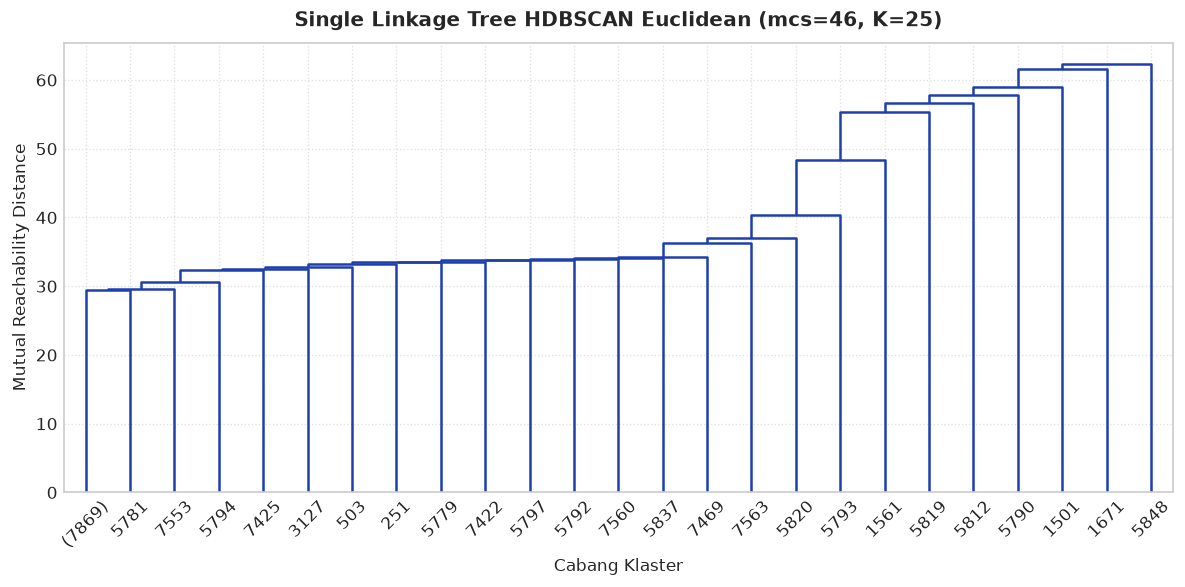

In [3]:
# =======================================================================
# 2. EKSEKUSI HDBSCAN EUCLIDEAN
# =======================================================================
t0 = time.perf_counter()
hdb = HDBSCAN(min_cluster_size=MCS, metric='euclidean', copy=True)
labels = hdb.fit_predict(X_scaled)
runtime = time.perf_counter() - t0

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
noise_count = int(np.sum(labels == -1))
noise_ratio = (noise_count / len(labels)) * 100.0

print(f"[INFO] HDBSCAN Euclidean Selesai dalam {runtime:.4f} detik.")
print(f"[INFO] Jumlah Klaster Ditemukan: {n_clusters}")
print(f"[INFO] Jumlah Sampel Noise: {noise_count} ({noise_ratio:.2f}%)")

# Visualisasi Dendrogram Single Linkage Tree
tree_data = hdb._single_linkage_tree_
if hasattr(tree_data, 'dtype') and tree_data.dtype.names is not None:
    Z_scipy = np.column_stack([tree_data[name] for name in tree_data.dtype.names]).astype(float)
else:
    Z_scipy = np.array(tree_data, dtype=float)

plt.figure(figsize=(10, 5))
dendrogram(
    Z_scipy,
    truncate_mode='lastp',
    p=n_clusters,
    show_leaf_counts=True,
    above_threshold_color='#1E40AF',
    color_threshold=0
)
plt.title(f'Single Linkage Tree HDBSCAN Euclidean (mcs={MCS}, K={n_clusters})', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Cabang Klaster', fontsize=10)
plt.ylabel('Mutual Reachability Distance', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

dendro_path = os.path.join(OUTPUT_DIR, "dendrogram_euclidean.png")
plt.savefig(dendro_path, dpi=300)
print(f"[SAVE] Grafik disimpan ke: '{dendro_path}'")
plt.show()

In [4]:
# =======================================================================
# 3. EVALUASI METRIK KUANTITATIF EUCLIDEAN
# =======================================================================
mask = labels != -1
sil = float(silhouette_score(X_scaled[mask], labels[mask], metric='euclidean'))
db = float(davies_bouldin_score(X_scaled[mask], labels[mask]))
ch = float(calinski_harabasz_score(X_scaled[mask], labels[mask]))

df_res = pd.DataFrame([{
    'Distance Metric': 'Euclidean Distance (L2)',
    'Min Cluster Size': MCS,
    'Clusters Found': n_clusters,
    'Noise Samples (↓)': noise_count,
    'Noise Ratio (%) (↓)': round(noise_ratio, 2),
    'Clustered Samples (↑)': len(labels) - noise_count,
    'Silhouette Score (↑)': round(sil, 4),
    'Davies–Bouldin Index (↓)': round(db, 4),
    'Calinski–Harabasz Index (↑)': round(ch, 2),
    'Execution Time (s) (↓)': round(runtime, 4)
}])

print("\n" + "="*85)
print(df_res.to_string(index=False))
print("="*85)

excel_out = os.path.join(OUTPUT_DIR, "evaluasi_hdbscan_euclidean.xlsx")
df_data_out = df_meta.copy()
df_data_out['cluster_euclidean'] = labels
df_data_out['prob_euclidean'] = hdb.probabilities_

with pd.ExcelWriter(excel_out, engine='openpyxl') as writer:
    df_res.to_excel(writer, sheet_name='Ringkasan_Metrik', index=False)
    pd.Series(labels).value_counts().to_frame(name='Jumlah_Sampel').to_excel(writer, sheet_name='Distribusi_Klaster')
    df_data_out.head(1000).to_excel(writer, sheet_name='Sampel_Prediksi_1000', index=False)

print(f"[SAVE] Berkas evaluasi Excel disimpan ke: '{excel_out}'")


        Distance Metric  Min Cluster Size  Clusters Found  Noise Samples (↓)  Noise Ratio (%) (↓)  Clustered Samples (↑)  Silhouette Score (↑)  Davies–Bouldin Index (↓)  Calinski–Harabasz Index (↑)  Execution Time (s) (↓)
Euclidean Distance (L2)                46              25               3937                49.88                   3956                0.3486                    0.7467                       513.99                  5.5503


[SAVE] Berkas evaluasi Excel disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\HDBScan\outputHDBScan\evaluasi_hdbscan_euclidean.xlsx'


[SAVE] Grafik disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\HDBScan\outputHDBScan\cluster_euclidean.png'


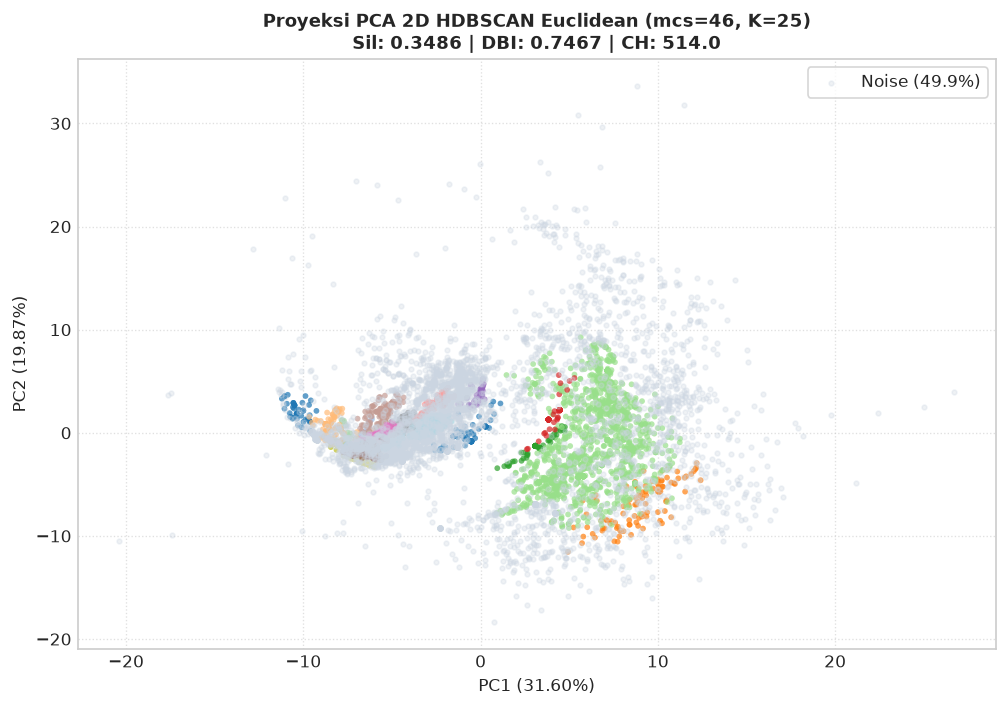

In [5]:
# =======================================================================
# 4. VISUALISASI SEBARAN KLASTER DAN NOISE PCA 2D
# =======================================================================
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8.5, 6))
plt.scatter(
    X_pca[mask, 0], X_pca[mask, 1],
    c=labels[mask], cmap='tab20', s=12, alpha=0.7, edgecolors='none'
)
plt.scatter(
    X_pca[~mask, 0], X_pca[~mask, 1],
    c='#CBD5E1', s=8, alpha=0.3, label=f'Noise ({noise_ratio:.1f}%)'
)
plt.title(f'Proyeksi PCA 2D HDBSCAN Euclidean (mcs={MCS}, K={n_clusters})\nSil: {sil:.4f} | DBI: {db:.4f} | CH: {ch:.1f}', fontsize=11, fontweight='bold')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', frameon=True, facecolor='white')
plt.tight_layout()

pca_path = os.path.join(OUTPUT_DIR, "cluster_euclidean.png")
plt.savefig(pca_path, dpi=300)
print(f"[SAVE] Grafik disimpan ke: '{pca_path}'")
plt.show()